# Laplace Iterative Solvers

## Problem
$$
u_{xx} + u_{yy} = 0, \quad u = 1 \text{ on } y = 1, \quad u = 0 \text{ on the other edges}
$$
Reference series, with 100 odd terms

$$
u = \sum_{n \text{ odd}} \frac{4}{n\pi} \sin(n\pi x) \frac{\sinh(n\pi y)}{\sinh(n\pi)}
$$

## Discretization
Five-point stencil with Jacobi, Gauss-Seidel and SOR sweeps, $\omega = 2/(1+\sin\pi h)$. Gauss-Seidel and SOR use red-black ordering so each sweep is vectorised. Iteration stops when the largest update is below $10^{-6}$.

## Code

In [1]:
import sys
sys.path.append('../src')
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from elliptic import jacobi, gauss_seidel, sor, laplace_series

In [2]:
def start(N):
    u = np.zeros((N+1, N+1))
    u[:, -1] = 1
    return u

In [3]:
results = []
for N in [8, 16, 32, 64]:
    h = 1/N
    w = 2/(1+np.sin(np.pi*h))
    uj, kj = jacobi(start(N), h)
    ug, kg = gauss_seidel(start(N), h)
    us, ks = sor(start(N), h, w)
    results.append({'N': N, 'jacobi': kj, 'gs': kg, 'sor': ks})
df = pd.DataFrame(results)
df

,N,jacobi,gs,sor
0,8,132,71,20
1,16,462,250,39
2,32,1570,858,73
3,64,5138,2857,140


In [4]:
for c in ['jacobi', 'gs', 'sor']:
    print(c, (df[c].shift(-1)/df[c]).round(2).values[:-1])

jacobi [3.5  3.4  3.27]
gs [3.52 3.43 3.33]
sor [1.95 1.87 1.92]


### Iterations

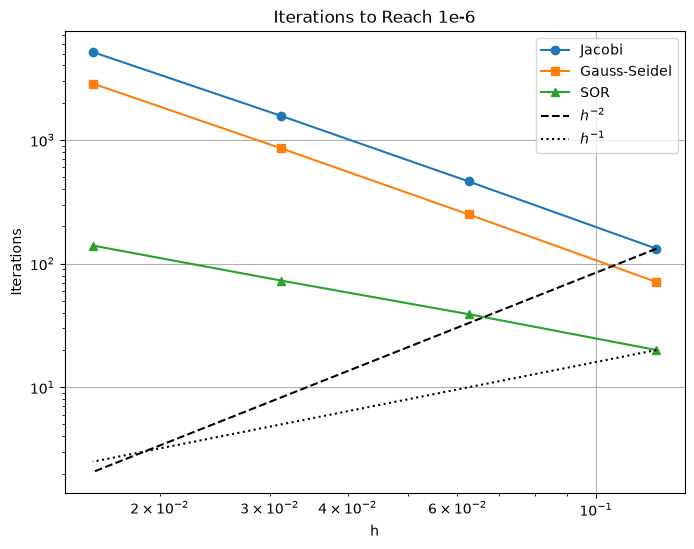

In [5]:
h = 1/df['N'].values
plt.figure(figsize=(8, 6))
plt.loglog(h, df['jacobi'], 'o-', label="Jacobi")
plt.loglog(h, df['gs'], 's-', label="Gauss-Seidel")
plt.loglog(h, df['sor'], '^-', label="SOR")
plt.loglog(h, df['jacobi'][0]*(h/h[0])**2, 'k--', label=r"$h^{-2}$")
plt.loglog(h, df['sor'][0]*(h/h[0]), 'k:', label=r"$h^{-1}$")
plt.xlabel("h")
plt.ylabel("Iterations")
plt.title("Iterations to Reach 1e-6")
plt.legend()
plt.grid(True)
plt.savefig("../figures/05_iterations.png", dpi=300, bbox_inches="tight")
plt.show()

### Solution

In [6]:
N = 64
h = 1/N
w = 2/(1+np.sin(np.pi*h))
u, k = sor(start(N), h, w)
x = np.linspace(0, 1, N+1)
X, Y = np.meshgrid(x, x, indexing='ij')
ref = laplace_series(X, Y)
np.max(np.abs(u-ref)[1:-1, 1:-1])

np.float64(0.007179846724149175)

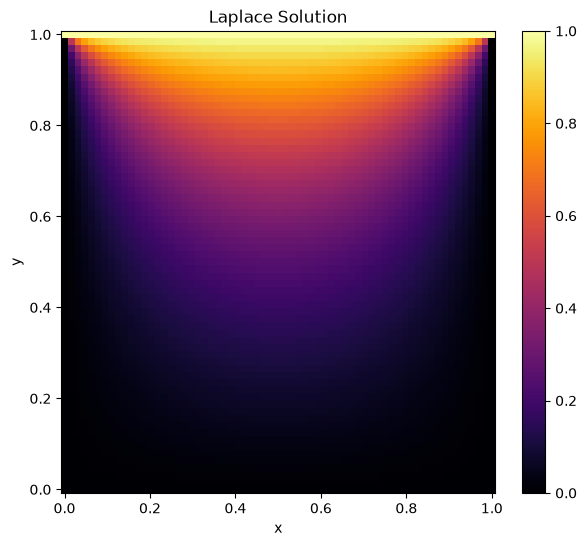

In [7]:
plt.figure(figsize=(7, 6))
plt.pcolormesh(X, Y, u, cmap='inferno', shading='auto')
plt.colorbar()
plt.xlabel("x")
plt.ylabel("y")
plt.title("Laplace Solution")
plt.savefig("../figures/05_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

## Conclusion
Jacobi and Gauss-Seidel need about 3.5 times more iterations each time h is halved, heading towards 4, while SOR needs about 2 times more. At N = 64 SOR needs 140 iterations against 5138 for Jacobi.